In [1]:
district_number = 7
chamber = 'Senate'

# Template district number
# Template chamber


match chamber:
    case 'House':
        race = f'State House of Representatives - District {district_number}'
        district_map_file = './gis/house-2023-shape.zip'
        previous_file = './data/state_house_2024.csv'

    case 'Senate':
        race = f'State Senate - District {district_number}'
        district_map_file = './gis/senate-2023-shape-file.zip'
        previous_file = './data/state_senate_2024.csv'

    case _:
        raise Exception(f'Unknown chamber: {chamber}')

import pandas as pd
import numpy as np

import sos
import colors

current_year = 2026
curr, candidates = sos.import_current(race, year=current_year)
curr = curr.rename(str.upper, level='Precinct')

prev = pd.read_csv(previous_file, index_col=['Race', 'County', 'Precinct']).loc[race]
prev = prev.rename(str.upper, level='Precinct')
prev_is_substitute = (prev['is_sub'] == 1).all()
prev = prev.drop(columns=['is_sub'])

curr[candidates[:2]] = prev.loc[curr.index.intersection(prev.index)][['Rep', 'Dem']] # Test
curr[candidates[:2]] = curr[candidates[:2]].fillna(0).astype(int)
curr

Aizaz Shahbaz Shaikh (Rep)  Ruwa Romman (Dem)  \
County   Precinct                                                             
Gwinnett 006 GOODWINS A                             1167               1498   
         007 DULUTH A                               1679               2263   
         026 HOG MOUNTAIN A                         1346               1919   
         040 PINCKNEYVILLE H                        1587               2005   
         048 DULUTH B                               1106               1213   
         056 DULUTH C                                689                802   
         057 DULUTH D                               1335               1967   
         060 LAWRENCEVILLE D                           0                  0   
         062 PINCKNEYVILLE L                        1176                792   
         063 PINCKNEYVILLE M                        1499                847   
         070 GOODWINS B                             1450               1368   
         077 GOODWINS C                             1440               2336   
         082 DULUTH E                               1136               2230   
         083 GOODWINS D                             1355               1498   
         085 LAWRENCEVILLE H                        1477               1514   
         090 LAWRENCEVILLE I                         799               1363   
         095 DULUTH F                               1034               2684   
         096 DULUTH G                               1148               1064   
         097 GOODWINS E                             1684               1997   
         098 GOODWINS F                              904               1160   
         099 PINCKNEYVILLE T                         933               1301   
         106 SUWANEE C                              2030               2140   
         111 DULUTH H                               1043               1143   
         114 PINCKNEYVILLE W                         926                934   
         121 PINCKNEYVILLE X                        1278               1455   
         124 GOODWINS G                              557               1055   
         125 PINCKNEYVILLE Z                         960                648   
         128 GOODWINS H                              995               1145   
         132 LAWRENCEVILLE K                        1119               1230   
         138 DULUTH I                               1812               1634   
         149 GOODWINS I                              832                962   
         150 DULUTH K                                357                946   
         155 SUWANEE G                              1369               1635   

                              Reported?  
County   Precinct                        
Gwinnett 006 GOODWINS A           False  
         007 DULUTH A             False  
         026 HOG MOUNTAIN A       False  
         040 PINCKNEYVILLE H      False  
         048 DULUTH B             False  
         056 DULUTH C             False  
         057 DULUTH D             False  
         060 LAWRENCEVILLE D      False  
         062 PINCKNEYVILLE L      False  
         063 PINCKNEYVILLE M      False  
         070 GOODWINS B           False  
         077 GOODWINS C           False  
         082 DULUTH E             False  
         083 GOODWINS D           False  
         085 LAWRENCEVILLE H      False  
         090 LAWRENCEVILLE I      False  
         095 DULUTH F             False  
         096 DULUTH G             False  
         097 GOODWINS E           False  
         098 GOODWINS F           False  
         099 PINCKNEYVILLE T      False  
         106 SUWANEE C            False  
         111 DULUTH H             False  
         114 PINCKNEYVILLE W      False  
         121 PINCKNEYVILLE X      False  
         124 GOODWINS G           False  
         125 PINCKNEYVILLE Z      False  
         128 GOODWINS H           False  
    

In [2]:
import utils

utils.mk_formatted_timestamp()

'As of Sunday, 1 November 2026 at 10:11 PM Eastern Time'

# Current tally

Below shows the current tally of votes for each candidate as shown on the [Secretary of State's website](https://results.sos.ga.gov/results/public/Georgia). It may or may not be a good reflection of the final result.

In [3]:
summary = pd.DataFrame(curr[candidates].sum().astype(int).sort_values(ascending=False), columns=['Votes'])
summary['Share'] = (summary['Votes'] / summary['Votes'].sum()).fillna(0)
(summary.style
 .format('{:,}', subset=['Votes'])
 .format('{:.2%}', subset=['Share']))

,Votes,Share
Ruwa Romman (Dem),"46,748",55.02%
Aizaz Shahbaz Shaikh (Rep),"38,222",44.98%


# Map

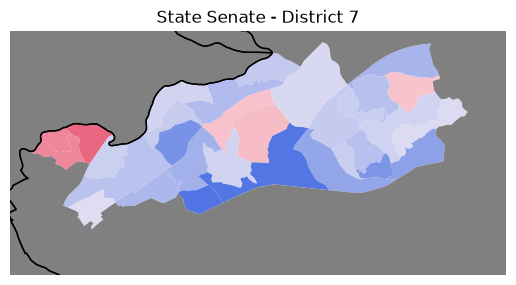

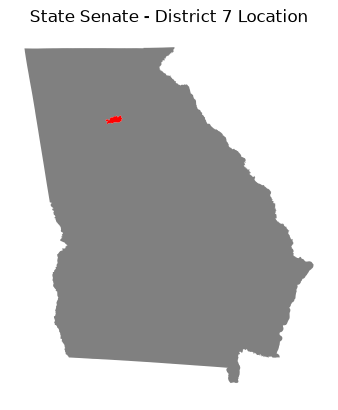

In [4]:
import geopandas
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Counties
counties = utils.import_county_map()

# Precincts
metro_prec_data = geopandas.read_file('./regions/regions_metro.json')
metro_prec_data = metro_prec_data.rename(columns={'index': 'Precinct'})
metro_prec_data = metro_prec_data.sort_index()

def sanitize_mpd(x, county: str, year, replace=' '):
    def worker(y):
        return replace.join(y.split(replace)[1:])
    x.loc[(x['County'] == county) & (x['Election'] == year), 'Precinct'] = \
        x.loc[(x['County'] == county) & (x['Election'] == year), 'Precinct'].apply(worker)
    return x

metro_prec_data = sanitize_mpd(metro_prec_data, 'Gwinnett', '2022')
metro_prec_data = sanitize_mpd(metro_prec_data, 'Hall', '2026', '-')

metro_prec_data['Precinct'] = metro_prec_data['Precinct'].apply(str.upper)

metro_prec_data = metro_prec_data.set_index(['Election', 'County', 'Precinct'])
metro_prec_data = metro_prec_data.sort_index()


current_metro_precs = metro_prec_data.loc[str(current_year)]
metro_counties = current_metro_precs.index.get_level_values('County').unique()
nonmetro_counties_geo = counties[~counties.index.isin(metro_counties)]
nonmetro_counties = nonmetro_counties_geo.index.intersection(curr.index.get_level_values('County'))
nonmetro_counties_geo.index = pd.MultiIndex.from_tuples([(county, county.upper()) for county in nonmetro_counties_geo.index])
mask = curr.index.intersection(current_metro_precs.index)
county_geometry = nonmetro_counties_geo.geometry.set_crs(current_metro_precs.crs)
geometry = pd.concat([current_metro_precs.geometry[mask], county_geometry])
# TODO: add sanity check to make sure all geometries selected


# Districts
district_map = geopandas.read_file(district_map_file)
district_map = district_map.set_index('DATA')

background_geo = district_map.drop(district_number).dissolve()

def second_max(k: np.ndarray):
    return np.sort(k)[-2]

unit_shares = curr[candidates].div(curr[candidates].sum(axis=1), axis=0).fillna(0) * 100
winners = curr[candidates].idxmax(axis=1)
winners[curr[candidates].max(axis=1) == curr[candidates].apply(second_max, axis=1)] = 'Tie'
winners[curr[candidates].sum(axis=1) == 0] = 'No results'
margins = unit_shares.max(axis=1) - unit_shares.apply(second_max, axis=1)

fig, ax = plt.subplots()
ax.set_title(race)

share_norm = mcolors.Normalize(-10, np.maximum(50, margins.max()))

for cand in candidates:
    party = colors.party_name(cand)

    match party:
        case 'Dem':
            color_scheme = colors.democrats
        case 'Rep':
            color_scheme = colors.republicans
        case _:
            color_scheme = colors.others

    selected = winners[winners == cand]
    if len(selected) == 0:
        continue

    #selected = selected[selected.index.intersection(geometry.index)]
    margins_selected = margins[selected.index]

    selected_geos = geopandas.GeoDataFrame(margins_selected, columns=['Margin'], geometry=geometry[selected.index])
    selected_geos.plot('Margin', cmap=color_scheme, ax=ax, norm=share_norm)

if 'No results' in winners.values:
    geometry[winners[winners == 'No results'].index].plot(color='lightgray', ax=ax)
if 'Tie' in winners.values:
    geometry[winners[winners == 'Tie'].index].plot(color='purple', ax=ax)

background_geo.plot(color='gray', ax=ax, autolim=False)
counties.plot(color='None', ax=ax, autolim=False)
ax.set_axis_off()
plt.show()

# Placement map
fig, ax = plt.subplots()
background_geo.plot(color='gray', ax=ax)
district_map.loc[[district_number]].plot(color='red', ax=ax)
ax.set_axis_off()
ax.set_title(f'{race} Location')
plt.show()

# Swingometer

Below you can see the two-party swing required to flip this seat. It also shows how close the challenger is to meeting that requirement. The "Swing Measured" variable is calculated only with regard to counties that have moved to Election Night Complete status, so it may not reflect the data you see on the Secretary of State's website or in the table at the top of the page.

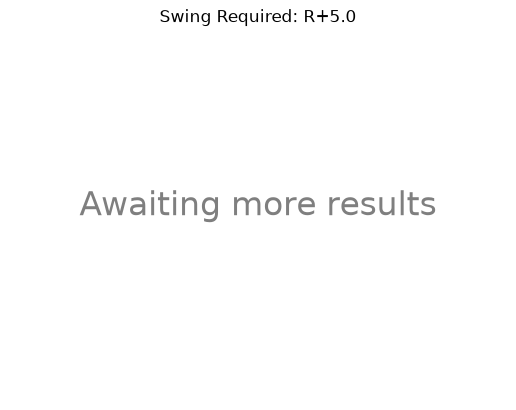

In [5]:
import dials

fig, ax = plt.subplots()

# Summate to Precinct Reporting Groups
curr_prg = curr.copy()
curr_prg['Reporting Group'] = metro_prec_data.loc[str(current_year)][f'Reporting Group (2024-{current_year})']
curr_prg.loc[nonmetro_counties, 'Reporting Group'] = 'All'
aggs = {cand: 'sum' for cand in candidates}
aggs['Reported?'] = 'all'
curr_prg = curr_prg.groupby(['County', 'Reporting Group']).agg(aggs)

prev_prg = prev.copy()
prev_prg['Reporting Group'] = metro_prec_data.loc['2024'][f'Reporting Group (2024-{current_year})']
prev_prg.loc[nonmetro_counties, 'Reporting Group'] = 'All'
prev_prg = prev_prg.groupby(['County', 'Reporting Group']).sum()



bm_table = prev.sum()
bm_table = bm_table / bm_table.sum() * 100.0
two_party_contest = len(candidates) == 2
swing_req_s = (bm_table['Dem'] - bm_table['Rep']) / 2.0 if two_party_contest else 50.0 - second_max(bm_table)
challenger_party = bm_table.idxmin()
swing_req = (challenger_party, np.abs(swing_req_s))
completed_counties = curr_prg[curr_prg['Reported?']]
benchmark_namer = {colors.party_name(cand): cand for cand in candidates}

if prev_is_substitute:
    if race == 'State House of Representatives - District 154':
        print('<b>Note</b>: This race is a little special. For races that were uncontested during the last cycle, we use the 2024 presidential election '
              'results as a benchmark instead. However, Harris won the district in 2024, while Republican Gerald Greene won the state house race. Therefore, ' \
              f'Greene must overperform Trump by at least {swing_req_s:.1f} points.')
        

    else:

        print('<b>Note</b>: because this race was uncontested during the last cycle, the 2024 presidential election results are used as a benchmark instead.')

def calculate_swing(curr_j: pd.DataFrame | pd.Series, prev_j: pd.DataFrame | pd.Series):
    return ((curr_j[benchmark_namer['Rep']] - prev_j['Rep']) - (curr_j[benchmark_namer['Dem']] - prev_j['Dem'])) / 2 \
        if two_party_contest else \
        (curr_j[benchmark_namer[challenger_party]] - prev_j[challenger_party])


ax.set_title(f'Swing Required: {utils.point_formatter(swing_req)}')
ax.set_axis_off()


if len(completed_counties) == 0:
    ax.text(0.5, 0.5, 'Awaiting more results', ha='center', fontsize=24, alpha=0.5)
    measured_swing_s = 0

else:
    share_table = completed_counties[candidates].sum()
    share_table = share_table / share_table.sum() * 100

    filtered_benchmark = prev_prg.loc[completed_counties.index].sum()
    filtered_benchmark = filtered_benchmark / filtered_benchmark.sum() * 100

    measured_swing_s = calculate_swing(share_table, filtered_benchmark)
    measured_swing = (challenger_party, measured_swing_s)

    dials.dial_from_swing_required(swing_req_s, ax=ax, swing=measured_swing_s, 
                                   pty=None if two_party_contest else challenger_party,
                                   gray_center=not two_party_contest)

    ax.text(0, -0.2, f'Swing Measured: {utils.point_formatter(measured_swing)}', ha='center')

plt.show()
# TODO: Do race counter and notifier for range tolerance leavings
# TODO: Adress obfuscation for statewide races
# TODO: US Senate and PSC elections statewide
# TODO: Automate SSH
# TODO: Figure out how to upload .htaccess

# Areas fully reporting

Areas appear on the list below once they have reached "Election Night Complete" status. That means they have counted all election day, early, and absentee votes. However, there may still be provisional ballots that may take days to adjudicate. State legislative races rarely see more than 1,000 provisional ballots, so they are unlikely to affect the result. Just know that "fully reporting" in this context means "fully reporting but for provisional ballots."

For counties inside the metro Atlanta area, we use precinct-level returns instead.

In [6]:
curr_prg_shares = curr_prg[candidates].div(curr_prg[candidates].sum(axis=1), axis=0).fillna(0) * 100
curr_prg_shares['Reported?'] = curr_prg['Reported?']
prev_prg_shares = prev_prg.div(prev_prg.sum(axis=1), axis=0).fillna(0) * 100

curr_prg_shares['Margin'] = curr_prg_shares[candidates].max(axis=1) - curr_prg_shares[candidates].apply(second_max, axis=1)
curr_prg_shares['Swing'] = calculate_swing(curr_prg_shares[candidates], prev_prg_shares)
swing_sizes = curr_prg_shares['Swing'].copy()
curr_prg_shares = curr_prg_shares.sort_values('Swing', ascending=False)
if not two_party_contest:
    curr_prg_shares['Swing'] = curr_prg_shares['Swing'].map(lambda ms: (challenger_party, ms))
showing_areas = curr_prg_shares[curr_prg_shares['Reported?']][['Margin', 'Swing']].rename(str.title, level='Reporting Group')
if (showing_areas.index.get_level_values('Reporting Group') == 'All').all():
    showing_areas = showing_areas.reset_index('Reporting Group').drop(columns='Reporting Group')
(showing_areas.style
    .format(utils.point_formatter, subset=['Margin', 'Swing'])
    .map(utils.points_format_block, subset=['Margin'])
    .map(utils.points_format_font, subset=['Swing']))

,Margin,Swing
County,,


# Estimated votes remaining

We use a variable called a Vote Growth Ratio to help us predict the total number of votes cast before they are all counted. The Vote Growth Ratio is calculated in each county/precinct. It is the ratio between the number of votes counted in the completed counties/precincts and the number of votes cast in the previous election. Like the regional swing model, it gets more accurate as the night carries on. 

## By geography

In [7]:
unreported_counties = curr_prg[~curr_prg['Reported?']]
completed_counties = curr_prg[curr_prg['Reported?']]
counted_votes_cc = completed_counties[candidates].sum().astype(int)
counted_votes = curr_prg[candidates].sum()
prev_total = prev_prg.loc[completed_counties.index].sum().sum()

growth_ratio = (counted_votes_cc.sum() / prev_total) if prev_total > 0 else 1.0

In [8]:
proj_totals = (prev_prg.loc[~curr_prg['Reported?']].sum(axis=1) * growth_ratio).astype(int)
proj_totals = np.maximum(proj_totals, unreported_counties[candidates].sum(axis=1))

projected_remaining = (proj_totals - unreported_counties[candidates].sum(axis=1)).fillna(0).astype(int)
proj_total_votes = proj_totals.sum() + counted_votes_cc.sum()

projected_remaining_by_cty = pd.DataFrame(projected_remaining.sort_values(ascending=False), columns=['Votes'])
projected_remaining_by_cty['Share'] = (projected_remaining / projected_remaining.sum() * 100).fillna(0)
(projected_remaining_by_cty.style
    .format('{:,}', subset=['Votes'])
    .format('{:.2f}%', subset=['Share']))

## Summary

This table shows whether the number of remaining votes is enough to change the result. If the number in the bottom row ("Estimated votes remaining") is greater than either of the other two numbers, there is still a possibility of change.

If the number of estimated votes remaining is greater than the number in the first row (Votes required to swap places in count) then it is still possible for the currently-trailing candidate to take the lead.

If the number of estimated votes remaining is greater than the number in the second row (Votes required to force/avoid runoff) then it is still an open question as to whether or not there will be a runoff. Note that for two-candidate races, these numbers are effectively the same.

If the margin is within the legal range for a recount, this will be indicated by a message just above the table.


In [9]:
import race_decider

race_decider.remaining_votes_summary(summary['Votes'], projected_remaining)

,0
Votes required to swap places in count,"8,527"
Votes required to force runoff,"8,526"
Estimated votes remaining,0


## Projection

Below is my current projection for each candidate, based on a uniform swing model. Counties/precincts that have not fully reported are projected using the swing calculated in the reported counties. The model gets more accurate as more counties finish reporting.

The table also shows the minimum and maximum possible shares of the votes each candidate could receive at this point. The minimum share is if all remaining votes were counted for another candidate, and the maximum share is if all remaining votes were counted for the given candidate. This is an obtuse, but fairly definitive way of determining the final outcome.

If a candidate's minimum vote share is greater than 50%, they must win.

In [10]:
import model

if len(completed_counties) == 0:
    proj_summ = pd.DataFrame(pd.Series(np.zeros(len(candidates)).astype(int), index=candidates, name='Projected Votes'))

else: 
    counted_swings = share_table.sub(filtered_benchmark, fill_value=0)
    projected = model.project(counted_swings, prev_prg.loc[~curr_prg['Reported?']], proj_totals, counted_votes_cc).drop(['Dem', 'Rep'])
    proj_summ = pd.DataFrame(projected, columns=['Projected Votes'])

proj_summ['Projected Share'] = (proj_summ['Projected Votes'] / proj_summ['Projected Votes'].sum()).fillna(0)
proj_summ['Min. Share'] = counted_votes / proj_total_votes
proj_summ['Max. Share'] = (counted_votes + projected_remaining.sum()) / proj_total_votes
(proj_summ.style
.format('{:,}', subset=['Projected Votes'])
.format('{:.2%}', subset=['Projected Share', 'Min. Share', 'Max. Share']))

,Projected Votes,Projected Share,Min. Share,Max. Share
Aizaz Shahbaz Shaikh (Rep),0,0.00%,44.98%,44.98%
Ruwa Romman (Dem),0,0.00%,55.02%,55.02%


In [11]:
swing_mean = swing_sizes.mean() # Does not necessarily equal measured swing
swing_std = swing_sizes.std()
swing_moe = swing_std / np.sqrt(len(swing_sizes)) * 1.96
conf_lower = swing_mean - swing_moe
conf_upper = swing_mean + swing_moe
votes_counted = counted_votes.sum() / proj_total_votes

f'It is estimated that {votes_counted:.2%} of the vote has been counted.'

'It is estimated that 100.00% of the vote has been counted.'